# Handwritten Digit Recognition ✍️
**Problem:** Look at a 28×28 pixel image of a handwritten digit and say which digit (0–9) it is.
**Type:** Image classification with a neural network (MLP) · **Dataset:** MNIST — 70,000 handwritten digits

## 1. Load MNIST

In [1]:
import numpy as np, urllib.request, io

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
data = np.load(io.BytesIO(urllib.request.urlopen(url).read()))
x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]
print(x_train.shape, x_test.shape)

# Scale pixels to 0-1 and flatten each image to 784 numbers
x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

# Use a 20,000-image subset for training so the notebook runs in a few minutes anywhere
rng = np.random.RandomState(42)
idx = rng.choice(len(x_train), 20000, replace=False)
x_tr, y_tr = x_train[idx], y_train[idx]
print("training on", x_tr.shape)

(60000, 28, 28) (10000, 28, 28)


training on (20000, 784)


## 2. Train a small neural network (MLP: 784 → 128 → 10)

In [2]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(hidden_layer_sizes=(128,), max_iter=20, random_state=42)
model.fit(x_tr, y_tr)
print("training done")

training done


/home/hatch/workspace/ai-projects-portfolio/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


## 3. Evaluate on the 10,000-image test set

In [3]:
from sklearn.metrics import accuracy_score

pred = model.predict(x_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.4f}")

Test accuracy: 0.9616


## 4. See what the model sees — predictions and mistakes

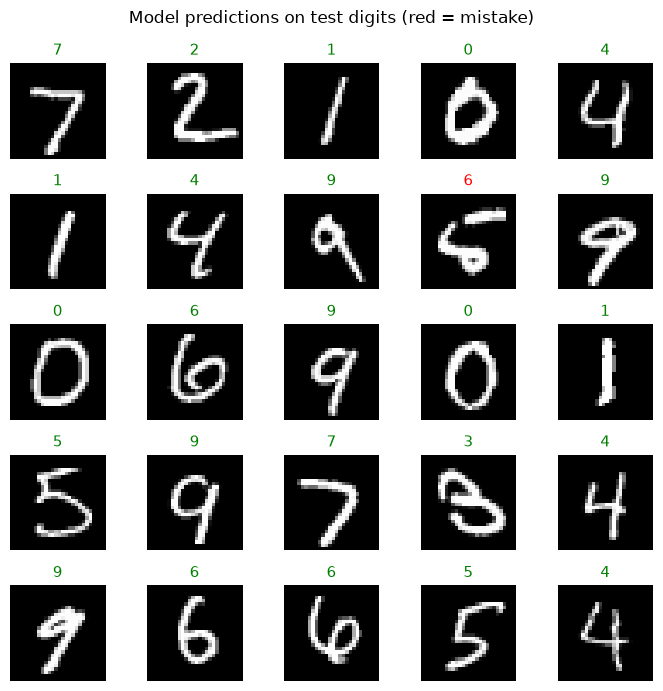

Total mistakes: 384 of 10000
First mistakes — true vs predicted: [(5, 6), (5, 3), (9, 3), (8, 7), (9, 8), (4, 2), (6, 0), (9, 1), (2, 7), (5, 3)]


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for ax, i in zip(axes.ravel(), range(25)):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ok = pred[i] == y_test[i]
    ax.set_title(f"{pred[i]}", color="green" if ok else "red", fontsize=11)
    ax.axis("off")
plt.suptitle("Model predictions on test digits (red = mistake)")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=150)
plt.show()

mistakes = np.where(pred != y_test)[0]
print(f"Total mistakes: {len(mistakes)} of {len(y_test)}")
print("First mistakes — true vs predicted:", [(int(y_test[i]), int(pred[i])) for i in mistakes[:10]])

## What I learned
- A plain one-hidden-layer network already reads handwriting with high accuracy — the magic is in the *data representation* (scaled pixels) and lots of examples.
- Most mistakes are genuinely ambiguous digits (4 vs 9, 3 vs 5) that humans also argue about.
- Training on the full 60,000 images, or using a CNN, pushes accuracy higher — a clear next step.